<a href="https://colab.research.google.com/github/LiliiaKuchvara/Python-DTA/blob/main/%D0%97%D0%B0%D0%BD%D1%8F%D1%82%D1%82%D1%8F_4_Feature_engineering_%D1%8F%D0%BA_%D1%81%D1%82%D0%B2%D0%BE%D1%80%D0%B8%D1%82%D0%B8_%D0%BE%D0%B7%D0%BD%D0%B0%D0%BA%D0%B8%2C_%D0%B7_%D1%8F%D0%BA%D0%B8%D0%BC%D0%B8_%D0%BC%D0%BE%D0%B4%D0%B5%D0%BB%D1%8C_%D0%BF%D1%80%D0%B0%D1%86%D1%8E%D1%94_%D0%BA%D1%80%D0%B0%D1%89%D0%B5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Заняття 4. Feature engineering: як створити ознаки, з якими модель працює краще

**Блок 2. Дані як основа ML**

## 1. Що таке ознака і навіщо її «конструювати»

Модель бачить лише **числа в колонках**. Вона не знає, що `2025-03-08 23:40` — це пізній вечір
свята, а `Shoes` — товар, який часто не підходить за розміром. **Feature engineering** — це
перекладання бізнес-знань у числові колонки.

| Сира колонка | Ознаки, які з неї можна зробити |
|---|---|
| дата й час замовлення | година, день тижня, місяць, «нічне замовлення», «вихідний» |
| категорія товару | по колонці 0/1 на кожну категорію (one-hot) |
| ціна і кількість | сума замовлення, сума знижки в грн |
| кількість попередніх замовлень | «перше замовлення» (0/1) |
| дата народження, дата найму | вік, стаж у роках |

**Правило:** найкращі ознаки народжуються з розуміння бізнесу. Запитайте себе: *«Від чого, на думку
людей з бізнесу, залежить результат?»*

## 2. Демонстрація: які замовлення повернуть

Інтернет-магазин втрачає гроші на поверненнях (доставка в обидва боки). Хоче заздалегідь знати
ризикові замовлення, щоб, наприклад, телефонувати й уточнювати розмір.

In [1]:
# Підготовка: бібліотеки та функція завантаження даних (працює в Colab і локально)
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 50)
DATA_URL = "https://raw.githubusercontent.com/KsiuTretyakova/ml_for_analys_dta_2026/refs/heads/main/data/"


def load_csv(name):
    """Читає CSV з поточної теки, з теки data/, з DATA_URL або просить завантажити файл у Colab."""
    for path in (name, os.path.join("data", name)):
        if os.path.exists(path):
            return pd.read_csv(path)
    if DATA_URL:
        return pd.read_csv(DATA_URL.rstrip("/") + "/" + name)
    from google.colab import files
    print(f"Натисніть «Choose files» і виберіть файл {name}")
    files.upload()
    return pd.read_csv(name)

In [2]:
orders = load_csv("online_orders.csv")
print(orders.shape, "| частка повернень:", round(orders["returned"].mean(), 3))
orders.head()

(8000, 13) | частка повернень: 0.272


,order_id,customer_id,order_datetime,category,price_uah,quantity,discount_pct,delivery_city,delivery_days,payment_method,device,customer_prev_orders,returned
0,O705785,U3382,2025-01-01 00:29,Books,721.0,1,0,Kyiv,5,card,mobile,0,1
1,O703152,U1169,2025-01-01 01:12,Clothing,1033.0,1,10,Other,7,cash_on_delivery,app,2,1
2,O702804,U3610,2025-01-01 02:08,Shoes,1808.0,1,20,Other,5,card,mobile,4,0
3,O704501,U2704,2025-01-01 03:19,Clothing,982.0,1,5,Odesa,4,cash_on_delivery,desktop,1,1
4,O701323,U1515,2025-01-01 03:19,Electronics,14470.0,1,5,Kyiv,5,cash_on_delivery,mobile,4,0


### Як порівнювати моделі: ROC-AUC

Сьогодні порівнюватимемо моделі за **ROC-AUC *(Receiver Operating Characteristic — Area Under Curve)***. Поки що достатньо простого розуміння:

> Візьмемо випадкове замовлення, яке повернули, і випадкове, яке не повернули.
> ROC-AUC — імовірність того, що модель дасть першому вищий «ризик», ніж другому.

0.5 — модель вгадує навмання, 1.0 — ідеально.

### Крок 1. Модель «як є» — лише готові числові колонки

In [3]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

train, test = train_test_split(orders, test_size=0.25, random_state=42, stratify=orders["returned"])

raw_num = ["price_uah", "quantity", "discount_pct", "delivery_days", "customer_prev_orders"]
lr_raw = LogisticRegression(max_iter=1000).fit(train[raw_num], train["returned"])
auc_raw = roc_auc_score(test["returned"], lr_raw.predict_proba(test[raw_num])[:, 1])
print(f"ROC-AUC лише на сирих числових колонках: {auc_raw:.3f}")

ROC-AUC лише на сирих числових колонках: 0.640


`predict_proba(...)[:, 1]` — це оцінка ймовірності класу 1 («повернуть») для кожного замовлення.

### Крок 2. Створюємо ознаки

Пишемо **одну функцію**, яка додає ознаки. Її застосуємо і до навчальних, і до нових даних.

In [4]:
def add_order_features(df):
    df = df.copy()
    dt = pd.to_datetime(df["order_datetime"])
    df["hour"] = dt.dt.hour
    df["weekday"] = dt.dt.day_of_week                       # 0 - понеділок
    df["is_weekend"] = (df["weekday"] >= 5).astype(int)
    df["is_night"] = ((df["hour"] >= 23) | (df["hour"] < 5)).astype(int)
    df["order_value_uah"] = df["price_uah"] * df["quantity"]
    df["discount_uah"] = df["order_value_uah"] * df["discount_pct"] / 100
    df["is_first_order"] = (df["customer_prev_orders"] == 0).astype(int)
    df["is_loyal"] = (df["customer_prev_orders"] > 3).astype(int)
    df["multi_items"] = (df["quantity"] > 1).astype(int)
    return df

train_f = add_order_features(train)
test_f = add_order_features(test)
train_f[["order_datetime", "hour", "is_night", "order_value_uah", "discount_uah", "is_first_order"]].head()

,order_datetime,hour,is_night,order_value_uah,discount_uah,is_first_order
2347,2025-04-16 19:36,19,0,1115.0,111.5,0
7604,2025-12-13 15:00,15,0,4414.0,441.4,0
7074,2025-11-19 07:38,7,0,13540.0,2708.0,0
3723,2025-06-17 04:49,4,1,490.0,24.5,0
4097,2025-07-03 19:12,19,0,949.0,0.0,0


### Крок 3. Категорії: one-hot кодування

`category = Shoes` перетворюється на колонку `category_Shoes = 1`, а решта колонок категорій — 0.
`handle_unknown="ignore"` — якщо в нових даних з'явиться нова категорія, модель не впаде.

In [5]:
from sklearn.preprocessing import OneHotEncoder

ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
ohe.fit(train_f[["category"]])
pd.DataFrame(ohe.transform(train_f[["category"]].head()), columns=ohe.get_feature_names_out())

,category_Beauty,category_Books,category_Clothing,category_Electronics,category_Home,category_Shoes
0,0.0,0.0,1.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,1.0,0.0
2,0.0,0.0,0.0,1.0,0.0,0.0
3,0.0,1.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,1.0,0.0


In [6]:
train_f.head()

,order_id,customer_id,order_datetime,category,price_uah,quantity,discount_pct,delivery_city,delivery_days,payment_method,device,customer_prev_orders,returned,hour,weekday,is_weekend,is_night,order_value_uah,discount_uah,is_first_order,is_loyal,multi_items
2347,O707049,U4574,2025-04-16 19:36,Clothing,1115.0,1,10,Dnipro,1,card,desktop,5,1,19,2,0,0,1115.0,111.5,0,1,0
7604,O703582,U4701,2025-12-13 15:00,Home,2207.0,2,10,Kyiv,2,card,mobile,8,1,15,5,1,0,4414.0,441.4,0,1,1
7074,O707429,U4287,2025-11-19 07:38,Electronics,6770.0,2,20,Kyiv,4,card,app,7,0,7,2,0,0,13540.0,2708.0,0,1,1
3723,O700370,U4901,2025-06-17 04:49,Books,490.0,1,5,Odesa,4,cash_on_delivery,mobile,1,0,4,1,0,1,490.0,24.5,0,0,0
4097,O707878,U4130,2025-07-03 19:12,Home,949.0,1,0,Kyiv,4,card,app,11,0,19,3,0,0,949.0,0.0,0,1,0


### Крок 4. Збираємо все в Pipeline

Обробок стає багато: числові колонки треба масштабувати (логістична регресія чутлива до масштабу),
категорії — кодувати. Робити це вручну для train і test — шлях до помилок.

- `ColumnTransformer` — «яку обробку застосувати до яких колонок»;
- `Pipeline` — «обробка → модель» як один об'єкт з методами `fit` і `predict`.

Pipeline сам навчає обробку лише на train (`fit`) — витоку немає.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

num_features = ["price_uah", "quantity", "discount_pct", "delivery_days", "customer_prev_orders",
                "hour", "is_weekend", "is_night", "order_value_uah", "discount_uah",
                "is_first_order", "is_loyal", "multi_items"]
cat_features = ["category", "delivery_city", "payment_method", "device"]

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features),
])
model = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=1000)),
])
model.fit(train_f, train_f["returned"])
auc_fe = roc_auc_score(test_f["returned"], model.predict_proba(test_f)[:, 1])
print(f"ROC-AUC: сирі колонки {auc_raw:.3f} -> після feature engineering {auc_fe:.3f}")

ROC-AUC: сирі колонки 0.640 -> після feature engineering 0.743


Та сама модель, ті самі рядки — але завдяки ознакам якість помітно вища. **Ознаки часто важать
більше, ніж вибір моделі.**

Подивимося, які ознаки модель вважає найважливішими (коефіцієнти після масштабування можна
порівнювати між собою: більше за модулем — сильніший вплив).

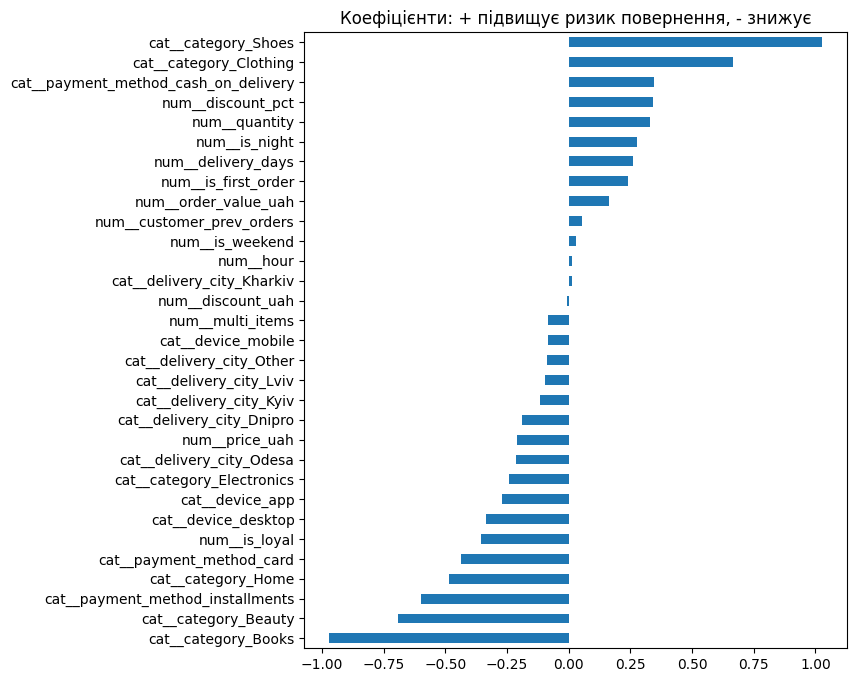

In [8]:
coefs = pd.Series(model.named_steps["clf"].coef_[0],
                  index=model.named_steps["prep"].get_feature_names_out()).sort_values()
coefs.plot.barh(figsize=(7, 8), title="Коефіцієнти: + підвищує ризик повернення, - знижує")
plt.show()

Взуття й одяг, оплата при отриманні, нічні замовлення, перші замовлення підвищують ризик; книги й
постійні клієнти — знижують. Ці висновки бізнес може перевірити здоровим глуздом.

### Крок 5. Модель для нового замовлення

Pipeline приймає «сирі» колонки — нове замовлення просто проходить ту саму функцію ознак.

In [9]:
new_order = pd.DataFrame([{
    "order_id": "O-NEW", "customer_id": "U1", "order_datetime": "2026-01-10 23:55",
    "category": "Shoes", "price_uah": 2400, "quantity": 2, "discount_pct": 30,
    "delivery_city": "Other", "delivery_days": 5, "payment_method": "cash_on_delivery",
    "device": "mobile", "customer_prev_orders": 5,
}])
risk = model.predict_proba(add_order_features(new_order))[:, 1][0]
print(f"Оцінка ризику повернення: {risk:.0%}")

Оцінка ризику повернення: 78%


### Обережно: витік через ознаки

Спокуслива ознака — «частка повернень цього клієнта». Якщо порахувати її по **всіх** даних,
вона містить відповідь для поточного замовлення. Такі ознаки рахують лише за **минулими** подіями
до моменту прогнозу. Перевіряйте кожну нову ознаку тим самим запитанням: *«Чи знатиму я це в момент
прогнозу?»*

---
## 3. Практика: хто з працівників звільниться

HR-відділ хоче знати, кому з працівників варто запропонувати розмову про розвиток, щоб зменшити
плинність. Дані `hr_attrition.csv` — знімок на `2025-12-31`; ціль — `left_company`.

### Завдання 1. Огляд і орієнтир

Завантажте дані, подивіться на типи колонок і частку тих, хто звільнився. Розділіть на train/test
(25 %, `random_state=42`, `stratify`). Навчіть `LogisticRegression(max_iter=1000)` лише на готових
числових колонках (без дат і `department`) і порахуйте ROC-AUC.

In [10]:
hr = load_csv("hr_attrition.csv")
# Ваш код тут
print(hr.dtypes)
print("\nЧастка звільнень:", round(hr['left_company'].mean(), 3), "\n")
hr.head()

employee_id              object
birth_date               object
hire_date                object
department               object
job_level                 int64
monthly_salary_uah      float64
last_raise_date          object
overtime_hours_month      int64
remote_days_week          int64
satisfaction_score        int64
performance_score         int64
commute_km              float64
trainings_last_year       int64
manager_changes_2y        int64
left_company              int64
dtype: object

Частка звільнень: 0.136 



,employee_id,birth_date,hire_date,department,job_level,monthly_salary_uah,last_raise_date,overtime_hours_month,remote_days_week,satisfaction_score,performance_score,commute_km,trainings_last_year,manager_changes_2y,left_company
0,E3000,1992-03-11,2021-02-25,Support,1,14600.0,2025-11-01,33,2,2,5,13.8,1,0,0
1,E3001,2000-04-22,2025-03-29,Support,4,41900.0,2025-06-04,39,0,3,3,7.3,0,0,0
2,E3002,1992-11-02,2025-04-11,Support,2,22100.0,2025-05-05,10,0,4,3,22.8,0,0,0
3,E3003,1986-10-18,2021-04-18,IT,1,27200.0,2024-08-08,15,3,2,4,22.2,2,0,1
4,E3004,1995-10-04,2025-10-27,Sales,2,34900.0,2025-11-01,13,5,4,3,11.3,0,0,0


In [11]:
hr_train, hr_test = train_test_split(hr, test_size=25, random_state=42, stratify=hr['left_company'])

hr_raw = ['job_level', 'monthly_salary_uah', 'overtime_hours_month',
          'remote_days_week', 'satisfaction_score', 'performance_score',
          'commute_km', 'trainings_last_year', 'manager_changes_2y']

base = Pipeline([
    ('sc', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000))
])

base.fit(hr_train[hr_raw], hr_train['left_company'])

auc_hr_raw = roc_auc_score(hr_test['left_company'], base.predict_proba(hr_test[hr_raw])[:,1])
print(f"ROC-AUC for raw: {auc_hr_raw:.3f}")

ROC-AUC for raw: 0.803


### Завдання 2. Ознаки з дат і бізнес-ознаки

Напишіть функцію `add_hr_features(df)`, що додає:
- `age` — вік у роках на `2025-12-31`;
- `tenure_years` — стаж у компанії;
- `months_since_raise` — місяців від останнього підвищення;
- `salary_vs_dept` — зарплата, поділена на медіанну зарплату свого відділу;
- `long_commute_office` — 1, якщо дорога > 20 км і віддалених днів ≤ 1.

*Підказка:* різниця дат дає `Timedelta`; `.dt.days / 365.25` — роки.
Медіану відділу для `salary_vs_dept` рахуйте за `groupby(...).transform("median")`.

In [12]:

def add_hr_features(df):
    df = df.copy()

    # Фіксована дата зрізу даних
    reference_date = pd.Timestamp("2025-12-31")

    # Перетворюємо дати
    birth = pd.to_datetime(df["birth_date"])
    hire = pd.to_datetime(df["hire_date"])
    raise_date = pd.to_datetime(df["last_raise_date"])

    # 1. Вік працівника
    df["age"] = (reference_date - birth).dt.days / 365.25

    # 2. Стаж роботи в компанії
    df["tenure_years"] = (reference_date - hire).dt.days / 365.25

    # 3. Місяці після останнього підвищення
    df["months_since_raise"] = (
        (reference_date - raise_date).dt.days / 30.4375
    )

    # 4. Зарплата відносно медіани свого відділу
    dept_median = df.groupby("department")[
        "monthly_salary_uah"
    ].transform("median")

    df["salary_vs_dept"] = (
        df["monthly_salary_uah"] / dept_median
    )

    # 5. Довга дорога та мало віддалених днів
    df["long_commute_office"] = (
        (df["commute_km"] > 20) &
        (df["remote_days_week"] <= 1)
    ).astype(int)

    return df


In [14]:
# Перевіряємо результат
hr_f = add_hr_features(hr)

hr_f[[
    "age",
    "tenure_years",
    "months_since_raise",
    "salary_vs_dept",
    "long_commute_office"
]].head()

,age,tenure_years,months_since_raise,salary_vs_dept,long_commute_office
0,33.806982,4.845996,1.971253,0.660633,0
1,25.691992,0.758385,6.899384,1.895928,0
2,33.160849,0.722793,7.885010,1.000000,1
3,39.203285,4.703628,16.755647,0.581197,0
4,30.242300,0.177960,1.971253,1.195205,0


### Завдання 3. Pipeline з категоріями

Зберіть `Pipeline`: `StandardScaler` для числових колонок (сирі + нові), `OneHotEncoder` для
`department`, модель `LogisticRegression(max_iter=1000)`. Порахуйте ROC-AUC і порівняйте із
завданням 1.

In [15]:

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score

# Сирі числові + нові ознаки
num_features = [
    "job_level",
    "monthly_salary_uah",
    "overtime_hours_month",
    "remote_days_week",
    "satisfaction_score",
    "performance_score",
    "commute_km",
    "trainings_last_year",
    "manager_changes_2y",
    "age",
    "tenure_years",
    "months_since_raise",
    "salary_vs_dept",
    "long_commute_office"
]

# Категоріальна ознака
cat_features = ["department"]


In [16]:
# Створюємо Pipeline

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_features),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_features)
])

model = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(max_iter=1000))
])


In [17]:
# Навчаємо модель і рахуємо ROC-AUC

# Додаємо нові ознаки до train і test
hr_train_f = add_hr_features(hr_train)
hr_test_f = add_hr_features(hr_test)

# Навчаємо модель
model.fit(hr_train_f, hr_train_f["left_company"])

# Прогнозуємо ймовірність звільнення
pred = model.predict_proba(hr_test_f)[:, 1]

# Рахуємо ROC-AUC
auc_hr_fe = roc_auc_score(hr_test_f["left_company"], pred)

print(f"ROC-AUC raw: {auc_hr_raw:.3f}")
print(f"ROC-AUC with feature engineering: {auc_hr_fe:.3f}")


ROC-AUC raw: 0.803
ROC-AUC with feature engineering: 0.727


In [18]:
# Порівнюємо результати
print(f"Різниця ROC-AUC: {auc_hr_fe - auc_hr_raw:+.3f}")

Різниця ROC-AUC: -0.076


In [19]:
# Порівнюємо модель без нових ознак
# і з кожною новою ознакою окремо

new_features = [
    "age",
    "tenure_years",
    "months_since_raise",
    "salary_vs_dept",
    "long_commute_office"
]

for feature in new_features:
    features = [
        col for col in num_features + cat_features
        if col != feature
    ]

    test_model = Pipeline([
        ("prep", ColumnTransformer([
            ("num", StandardScaler(),
             [c for c in features if c in num_features]),
            ("cat", OneHotEncoder(handle_unknown="ignore"),
             [c for c in features if c in cat_features])
        ])),
        ("clf", LogisticRegression(max_iter=1000))
    ])

    test_model.fit(hr_train_f, hr_train_f["left_company"])

    pred = test_model.predict_proba(hr_test_f)[:, 1]

    auc = roc_auc_score(hr_test_f["left_company"], pred)

    print(f"Без {feature}: ROC-AUC = {auc:.3f}")

Без age: ROC-AUC = 0.682
Без tenure_years: ROC-AUC = 0.636
Без months_since_raise: ROC-AUC = 0.803
Без salary_vs_dept: ROC-AUC = 0.773
Без long_commute_office: ROC-AUC = 0.697


### Завдання 4. Що впливає на звільнення

Побудуйте графік коефіцієнтів моделі (як у демонстрації). Назвіть три фактори, що найбільше
підвищують ризик звільнення, і три, що знижують. Чи погоджуєтеся ви з ними як людина, яка розуміє HR?

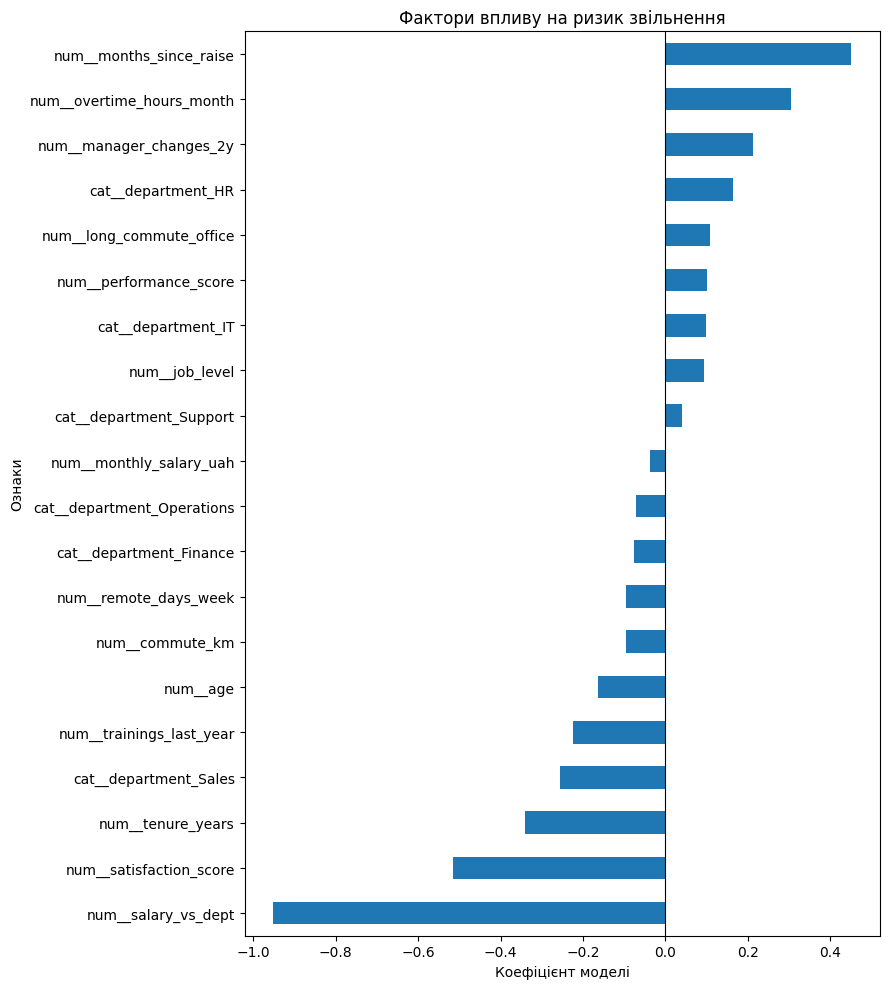

In [20]:
# Підвищують ризик: довго без підвищення, переробки, часті зміни керівника.
# Знижують: зарплата вища за медіану відділу, задоволеність, стаж у компанії.
# Ваш код тут

import pandas as pd
import matplotlib.pyplot as plt

# Отримуємо коефіцієнти логістичної регресії
coefs = pd.Series(
    model.named_steps["clf"].coef_[0],
    index=model.named_steps["prep"].get_feature_names_out()
).sort_values()

# Будуємо горизонтальний графік
coefs.plot.barh(
    figsize=(9, 10),
    title="Фактори впливу на ризик звільнення"
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Коефіцієнт моделі")
plt.ylabel("Ознаки")
plt.tight_layout()
plt.show()


In [21]:
print("ТРИ ФАКТОРИ, ЩО ПІДВИЩУЮТЬ РИЗИК:")
print(coefs.tail(3).sort_values(ascending=False))

print("\nТРИ ФАКТОРИ, ЩО ЗНИЖУЮТЬ РИЗИК:")
print(coefs.head(3))

ТРИ ФАКТОРИ, ЩО ПІДВИЩУЮТЬ РИЗИК:
num__months_since_raise      0.450847
num__overtime_hours_month    0.305982
num__manager_changes_2y      0.212443
dtype: float64

ТРИ ФАКТОРИ, ЩО ЗНИЖУЮТЬ РИЗИК:
num__salary_vs_dept       -0.951387
num__satisfaction_score   -0.515930
num__tenure_years         -0.341767
dtype: float64


### Завдання 5 (додатково). Подумайте про витік

Медіану зарплати у відділі ми рахували окремо в train і в test. Чи є тут витік цілі? А якби ми
додали ознаку «частка звільнених у відділі», порахувавши її по всіх даних? Відповідайте в
коментарі.

In [22]:
# Медіана зарплати не містить цілі - витоку цілі немає (хоча строго її краще рахувати лише на train
# і зберігати для нових даних). «Частка звільнених у відділі» по всіх даних містить left_company
# поточного працівника і test-даних - це витік. Рахувати її можна лише за минулими періодами.
# Ваш код тут

# Медіана зарплати у відділі не містить інформації про left_company,
# тому витоку цілі немає. Проте правильніше обчислювати медіани
# лише на train і використовувати їх для test та нових даних.

# Якщо додати ознаку "частка звільнених у відділі", розраховану
# за всіма даними, виникне витік цілі, оскільки вона використовує
# left_company, зокрема значення тестової вибірки та поточного працівника.

# Таку ознаку можна створювати лише на основі минулих даних,
# які були доступні на момент прогнозування.


---
## Підсумок

- Ознаки — це бізнес-знання, перекладені в числа. Вони часто важать більше, ніж модель.
- Дати → компоненти й різниці; категорії → one-hot; суми, частки, прапорці → з наявних колонок.
- `ColumnTransformer` + `Pipeline` — один об'єкт «обробка + модель», без витоку.
- Кожну нову ознаку перевіряємо: *«Чи знатиму я це в момент прогнозу?»*

## Загальний висновок до заняття 4. Feature Engineering

Під час виконання практичної роботи я ознайомилася з Feature Engineering — процесом створення нових ознак на основі наявних даних для покращення якості машинного навчання.

У першій частині роботи на прикладі інтернет-магазину було досліджено прогнозування повернення замовлень. Завдяки створенню додаткових ознак, таких як час замовлення, нічні замовлення, перше замовлення, загальна вартість покупки та сума знижки, вдалося підвищити ROC-AUC логістичної регресії з **0.640 до 0.743**. Це показало, що правильно підібрані ознаки можуть суттєво покращити прогнозування навіть без зміни алгоритму.

У другій частині роботи було досліджено прогнозування звільнення працівників. Було створено п'ять нових ознак: вік, стаж роботи, кількість місяців після останнього підвищення зарплати, співвідношення зарплати до медіани відділу та індикатор довгої дороги до офісу. Базова модель показала ROC-AUC **0.803**, тоді як модель з усіма новими ознаками — **0.727**. Це означає, що додавання нових ознак не завжди покращує якість моделі.

Після аналізу коефіцієнтів логістичної регресії було визначено основні фактори, пов'язані з ризиком звільнення. Найбільше його підвищують тривалий період без підвищення зарплати, велика кількість понаднормових годин і часті зміни керівника. Знижують ризик вища зарплата відносно медіани відділу, висока задоволеність роботою та більший стаж у компанії. Отримані результати загалом відповідають логіці HR та можуть допомогти визначити напрями роботи з утримання персоналу.

Також під час роботи було розглянуто проблему витоку даних. Я зрозуміла, що модель повинна використовувати лише ту інформацію, яка реально доступна на момент прогнозування. Особливо важливо не використовувати майбутні події або цільову змінну під час створення ознак.

Для побудови моделей було використано `StandardScaler`, `OneHotEncoder`, `ColumnTransformer` та `Pipeline`, що дозволило об'єднати обробку даних і навчання моделі в єдиний процес.

**Отже, головний висновок роботи полягає в тому, що якість машинного навчання залежить не лише від вибору алгоритму, а й від правильного створення, відбору та перевірки ознак. Feature Engineering допомагає перетворити звичайні дані на корисну інформацію для прийняття бізнес-рішень. Водночас кожну нову ознаку потрібно перевіряти експериментально, оскільки не всі вони покращують прогнозування.**